In [1]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import pandas as pd

In [3]:
df = pd.read_csv('speechsentiment.csv')

In [4]:
df.head()

,Unnamed: 0,Personality,Title,Sentence,Context,sentiment
0,Date,Martin Luther King Jr.,Paul's Letter to American Christians,Mr.,"Civil rights, unity, morality, technology, spi...",0.997602
1,03-06-1958 00:00,Martin Luther King Jr.,Paul's Letter to American Christians,"Chairman, distinguished platform associates, l...","Civil rights, unity, morality, technology, spi...",0.999852
2,03-06-1958 00:00,Martin Luther King Jr.,Paul's Letter to American Christians,I want to express my personal appreciation to ...,"Civil rights, unity, morality, technology, spi...",0.999748
3,03-06-1958 00:00,Martin Luther King Jr.,Paul's Letter to American Christians,I must apologize for being late this morning b...,"Civil rights, unity, morality, technology, spi...",0.989977
4,03-06-1958 00:00,Martin Luther King Jr.,Paul's Letter to American Christians,I can assure you if I had been in town earlier...,"Civil rights, unity, morality, technology, spi...",-0.996238


In [53]:

df.dropna(inplace=True)

dfs = []


grouped = df.groupby('Title')


for _, group in grouped:
    
    num_chunks = len(group) // 32
    
    
    for i in range(num_chunks):
        chunk = group.iloc[i*32:(i+1)*32]
        dfs.append(chunk)



In [54]:
#performing k means with chunks of 32 records and one feature, sentiment score
sentiment_scores = [chunk['sentiment'].mean() for chunk in dfs]


import numpy as np
sentiment_scores_np = np.array(sentiment_scores).reshape(-1, 1)  





In [55]:
from sklearn.cluster import KMeans


k = 3
kmeans = KMeans(n_clusters=k, random_state=0).fit(sentiment_scores_np)


clusters = kmeans.labels_
print(clusters)

[0 0 2 2 0 0 0 1 0 2 2 2 1 1 0 0 2 0 1 1 1 2 0 2 1 1 1 0 1 0 0 0 0 1]


C:\Users\aryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


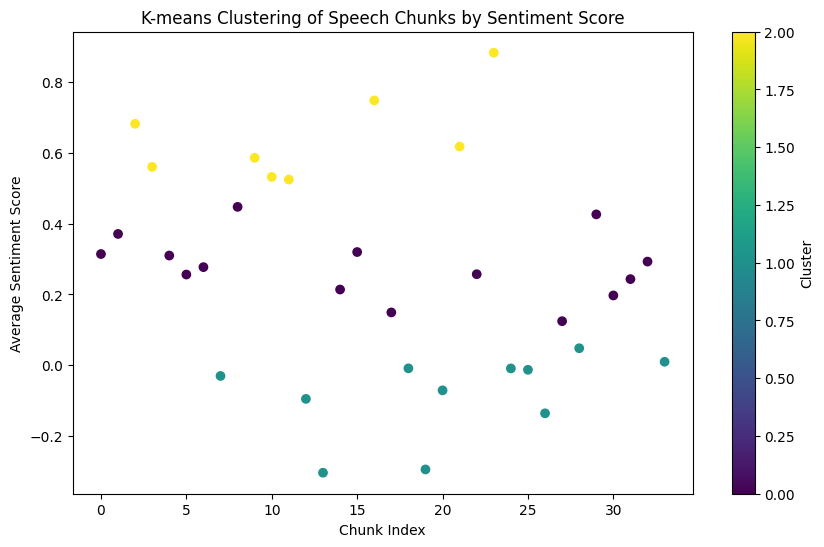

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(range(len(sentiment_scores)), sentiment_scores, c=clusters, cmap='viridis')
plt.title('K-means Clustering of Speech Chunks by Sentiment Score')
plt.xlabel('Chunk Index')
plt.ylabel('Average Sentiment Score')
plt.colorbar(label='Cluster')
plt.show()



In [20]:
df.dropna(inplace=True)

dfs = []


grouped = df.groupby('Title')


for _, group in grouped:
    
    num_chunks = len(group) // 16
    
    
    for i in range(num_chunks):
        chunk = group.iloc[i*16:(i+1)*16]
        dfs.append(chunk)


In [21]:
sentiment_scores = [chunk['sentiment'].mean() for chunk in dfs]


import numpy as np
sentiment_scores_np = np.array(sentiment_scores).reshape(-1, 1)  

In [22]:
from sklearn.cluster import KMeans


k = 3
kmeans = KMeans(n_clusters=k, random_state=0).fit(sentiment_scores_np)


clusters = kmeans.labels_
print(clusters)

[1 1 1 1 2 2 1 2 1 2 2 1 1 1 1 2 0 0 1 2 1 2 1 1 2 2 1 1 0 0 0 0 1 1 1 2 2
 2 2 1 1 0 1 0 0 1 1 1 0 0 2 2 1 1 1 2 2 0 1 1 1 1 0 1 1 0 1 1 2 1 1 1 2 0
 1 2 0 1 1 1]


C:\Users\aryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


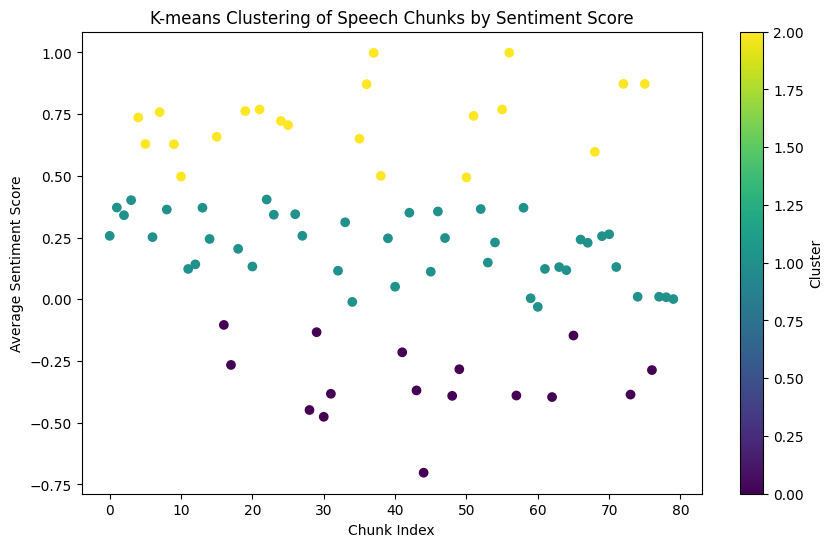

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(range(len(sentiment_scores)), sentiment_scores, c=clusters, cmap='viridis')
plt.title('K-means Clustering of Speech Chunks by Sentiment Score')
plt.xlabel('Chunk Index')
plt.ylabel('Average Sentiment Score')
plt.colorbar(label='Cluster')
plt.show()


In [24]:

for i, chunk in enumerate(dfs):
    chunk['Cluster'] = clusters[i]


df_with_clusters = pd.concat(dfs, ignore_index=True)




C:\Users\aryan\AppData\Local\Temp\ipykernel_24940\2097454136.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  chunk['Cluster'] = clusters[i]


In [25]:
df_with_clusters.head()

,Unnamed: 0,Personality,Title,Sentence,Context,sentiment,Cluster
0,03-12-1991 00:00,Nelson Mandela,\nDeputy President of the African National Con...,"Your Excellency Ambassador Ibrahim Gambari, Pe...","Addressing apartheid's end, hope.",0.998699,1
1,22-06-1990 00:00,Nelson Mandela,\nDeputy President of the African National Con...,"Joseph Garba, President of the General Assembl...","Addressing apartheid's end, hope.",0.999230,1
2,22-06-1990 00:00,Nelson Mandela,\nDeputy President of the African National Con...,"Javier Perez de Cuellar, Secretary-General of ...","Addressing apartheid's end, hope.",0.999816,1
3,22-06-1990 00:00,Nelson Mandela,\nDeputy President of the African National Con...,"We are most grateful to you, Mr.","Addressing apartheid's end, hope.",0.999822,1
4,22-06-1990 00:00,Nelson Mandela,\nDeputy President of the African National Con...,"Chairman, the Special Committee against Aparth...","Addressing apartheid's end, hope.",0.992898,1


In [26]:
df = pd.read_csv('speechsentiment.csv')
df.dropna(inplace=True)

dfs = []


grouped = df.groupby('Title')


for _, group in grouped:
    
    num_chunks = len(group) // 32
    
    
    for i in range(num_chunks):
        chunk = group.iloc[i*32:(i+1)*32]
        dfs.append(chunk)

In [27]:
tfidf_vectorizer = TfidfVectorizer(max_features=100)  
sentiment_scaler = StandardScaler()


aggregated_features = []

for df_chunk in dfs:

    tfidf_features = tfidf_vectorizer.fit_transform(df_chunk['Sentence']).toarray()
    avg_tfidf_features = tfidf_features.mean(axis=0).reshape(1, -1)
    
    sentiment_scores = df_chunk['sentiment'].values.reshape(-1, 1)
    scaled_sentiment_scores = sentiment_scaler.fit_transform(sentiment_scores)
    avg_sentiment_score = scaled_sentiment_scores.mean(axis=0).reshape(1, -1)
    

    combined_features = np.hstack((avg_tfidf_features, avg_sentiment_score))
    aggregated_features.append(combined_features)


aggregated_feature_matrix = np.vstack(aggregated_features)


In [28]:

k_dataframes = 3  
kmeans_df_clusters = KMeans(n_clusters=k_dataframes, random_state=42)
df_cluster_labels = kmeans_df_clusters.fit_predict(aggregated_feature_matrix)



C:\Users\aryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


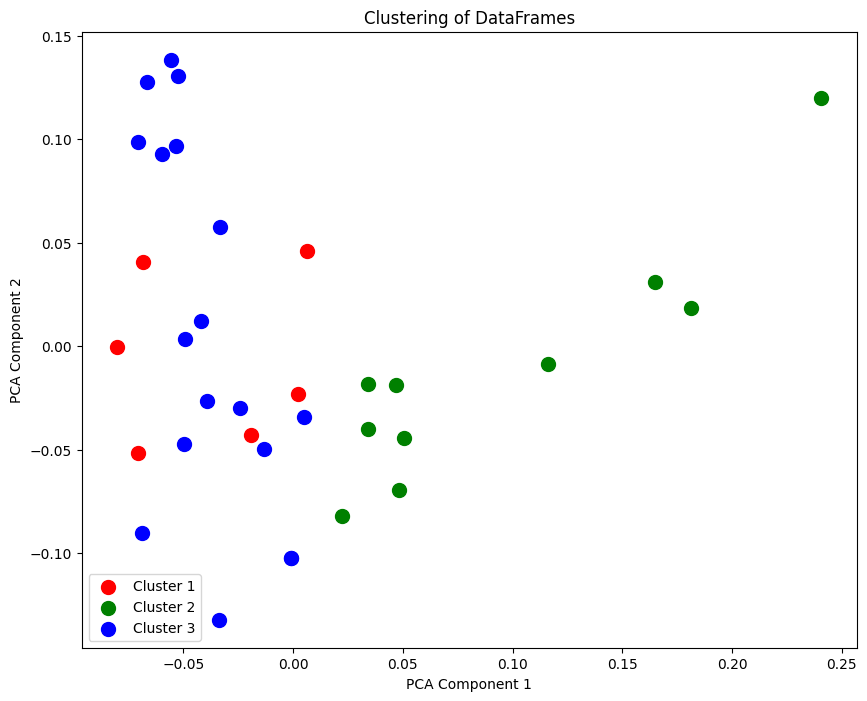

In [29]:

pca = PCA(n_components=2)
reduced_features = pca.fit_transform(aggregated_feature_matrix)

plt.figure(figsize=(10, 8))
colors = ['red', 'green', 'blue', 'purple', 'orange']

for i in range(k_dataframes):
    points = reduced_features[df_cluster_labels == i]
    plt.scatter(points[:, 0], points[:, 1], s=100, c=colors[i], label=f'Cluster {i+1}')

plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('Clustering of DataFrames')
plt.legend()
plt.show()
